# How much should we trust the merged model?

After merging the teammate's pipeline, the recommended model is **LightGBM on 141 features**: Phase 3 Steps 1-2, plus months since the first review and the quoted night's day of week. Its host-grouped CV error is about $85 a night. Before building more on it, this notebook asks how that number could be wrong.

| Risk | How it could happen here | Check |
|---|---|---|
| Model overfitting | Trees memorise training listings | §1 in-sample vs held-out gap, §2 learning curves |
| Selection overfitting | We tried many feature ideas on the same folds and kept the winners | §3 noise-feature test, §4 nested selection |
| Time drift | Trained on summer prices, used in another season | §5 June → September test |
| Over-confident ranges | The "80% range" may cover less than 80% | §5 interval coverage |
| Fragile tuning | Results depend on one lucky hyperparameter setting | §6 sensitivity |
| Systematic errors | Some kinds of listing are always over- or under-priced | §7 error analysis |

Every check keeps hosts apart between training and evaluation, as in all earlier phases.

In [1]:
import json, sys, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupKFold, GroupShuffleSplit
from sklearn.linear_model import RidgeCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, r2_score
import lightgbm as lgb

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
DATA, OUT, SEED = Path("../data"), Path("../interface"), 42
sys.path.insert(0, "../src")
import enriched_features as ef
import team_features as tf
_js = (OUT / "data.js").read_text(); BUNDLE = json.loads(_js[_js.index("{"): _js.rindex("}") + 1])
A, X, y, groups = ef.build_merged_matrix(DATA, BUNDLE["quarterly"]["zones"]["centers_km"])
KEPT = ["months_since_first_review"] + [c for c in X.columns if c.startswith("quote_dow_")]
BASE = X.drop(columns=KEPT)
LGB = dict(n_estimators=900, learning_rate=0.03, num_leaves=31, min_child_samples=20, subsample=0.8, subsample_freq=1,
           colsample_bytree=0.6, reg_lambda=1.0, random_state=SEED, verbose=-1)
# Repeated checks (learning curves, noise test, nested selection, tuning grid) use a faster LightGBM:
# 300 trees at learning rate 0.08 instead of 900 at 0.03. The headline CV error uses the full model.
FAST = {**LGB, "n_estimators": 300, "learning_rate": 0.08}
FOLDS = list(GroupKFold(5).split(X, y, groups))
mae = lambda yt, yp: mean_absolute_error(np.exp(yt), np.exp(yp))
print(X.shape, "| base without the merged ideas:", BASE.shape[1], "features")

(7039, 141) | base without the merged ideas: 133 features


## 1. In-sample vs held-out, every fold

R² on the rows a model was trained on, against R² on the held-out hosts. A large gap means the model memorises. It is only a *problem* if the held-out score is worse than a simpler model's.

In [2]:
imp = lambda est: Pipeline([("i", SimpleImputer(strategy="median", add_indicator=True)), ("s", StandardScaler()), ("m", est)])
MODELS = {
    "Ridge": lambda: imp(RidgeCV(alphas=np.logspace(-3, 3, 25))),
    "Random forest": lambda: Pipeline([("i", SimpleImputer(strategy="median", add_indicator=True)),
                                       ("m", RandomForestRegressor(n_estimators=300, max_features=0.33, random_state=SEED, n_jobs=-1))]),
    "Neural network (MLP)": lambda: imp(MLPRegressor(hidden_layer_sizes=(64, 32), alpha=3.0, max_iter=2000, early_stopping=True,
                                                     n_iter_no_change=30, random_state=SEED)),
    "LightGBM": lambda: lgb.LGBMRegressor(**LGB),
}
LC_MODELS = {**MODELS, "LightGBM": lambda: lgb.LGBMRegressor(**FAST),
             "Random forest": lambda: Pipeline([("i", SimpleImputer(strategy="median", add_indicator=True)),
                                                ("m", RandomForestRegressor(n_estimators=150, max_features=0.33, random_state=SEED, n_jobs=-1))])}
rows = []
for name, make in MODELS.items():
    for k, (a, b) in enumerate(FOLDS):
        m = make().fit(X.iloc[a], y[a])
        rows.append({"model": name, "fold": k, "train_R2": r2_score(y[a], m.predict(X.iloc[a])),
                     "heldout_R2": r2_score(y[b], m.predict(X.iloc[b])), "heldout_MAE": mae(y[b], m.predict(X.iloc[b]))})
gapdf = pd.DataFrame(rows)
gap = gapdf.groupby("model")[["train_R2", "heldout_R2", "heldout_MAE"]].agg(["mean", "std"]).round(3)
gap[("gap", "R2")] = (gap[("train_R2", "mean")] - gap[("heldout_R2", "mean")]).round(3)
gap.sort_values(("heldout_MAE", "mean"))

train_R2        heldout_R2        heldout_MAE         \
                         mean    std       mean    std        mean    std   
model                                                                       
LightGBM                0.976  0.001      0.795  0.030      84.738  6.345   
Random forest           0.982  0.001      0.768  0.025      90.984  7.276   
Ridge                   0.798  0.010      0.748  0.049      94.308  8.219   
Neural network (MLP)    0.894  0.009      0.742  0.035      94.869  7.350   

                        gap  
                         R2  
model                        
LightGBM              0.181  
Random forest         0.214  
Ridge                 0.050  
Neural network (MLP)  0.152

## 2. Learning curves: would more data help, and which model would gain most?

Each model is trained on 25% to 100% of every fold's training hosts (LightGBM and random forest in their faster settings) and scored on the same held-out hosts. A curve that is still falling at 100% means more data would help. This matters for deep learning: neural networks usually need the most data.

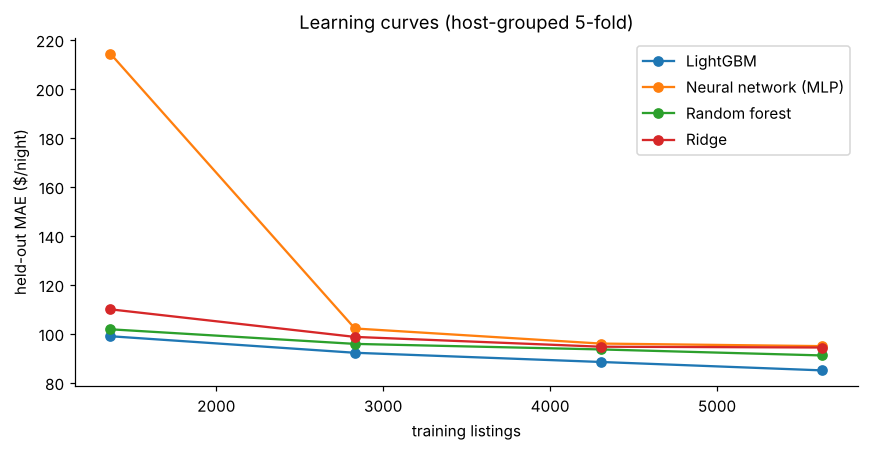

frac,0.25,0.5,0.75,1.0,gain from last 25% of data ($),gain 25%→100% ($)
model,,,,,,
LightGBM,98.91,92.16,88.41,84.96,3.44,13.94
Neural network (MLP),214.27,102.08,95.92,94.87,1.05,119.40
Random forest,101.74,95.79,93.53,91.07,2.46,10.68
Ridge,109.89,98.64,94.64,94.31,0.33,15.59


In [3]:
fracs = [0.25, 0.5, 0.75, 1.0]
lc = []
rng = np.random.default_rng(SEED)
for k, (a, b) in enumerate(FOLDS):
    hosts = np.unique(groups[a]); rng.shuffle(hosts)
    for f in fracs:
        keep_h = set(hosts[: max(1, int(len(hosts) * f))])
        aa = a[np.isin(groups[a], list(keep_h))]
        for name, make in LC_MODELS.items():
            m = make().fit(X.iloc[aa], y[aa])
            lc.append({"model": name, "fold": k, "frac": f, "n_train": len(aa), "MAE": mae(y[b], m.predict(X.iloc[b]))})
lc = pd.DataFrame(lc)
curve = lc.groupby(["model", "frac"]).agg(n_train=("n_train", "mean"), MAE=("MAE", "mean")).reset_index()
fig, ax = plt.subplots(figsize=(8, 4.2))
for name, g in curve.groupby("model"):
    ax.plot(g["n_train"], g["MAE"], marker="o", label=name)
ax.set_xlabel("training listings"); ax.set_ylabel("held-out MAE ($/night)"); ax.set_title("Learning curves (host-grouped 5-fold)"); ax.legend()
plt.tight_layout(); plt.show()
slope = curve.pivot(index="model", columns="frac", values="MAE")
slope["gain from last 25% of data ($)"] = slope[0.75] - slope[1.0]
slope["gain 25%→100% ($)"] = slope[0.25] - slope[1.0]
slope.round(2)

## 3. How often would our "keep" rule accept a useless feature?

Every idea in the merge was judged by the same rule: lower error, in at least 4 of 5 folds. To estimate the rule's false-positive rate, 15 features that **cannot** carry information are tested the same way: 5 random numbers, 5 random yes/no flags, and 5 real features shuffled across listings. The fast LightGBM setting is used for both the base and each noise test, so the comparison is like for like.

In [4]:
def cv_mae(Xm, params=LGB):
    return np.array([mae(y[b], lgb.LGBMRegressor(**params).fit(Xm.iloc[a], y[a]).predict(Xm.iloc[b])) for a, b in FOLDS])
base_err = cv_mae(BASE)                 # full model: the headline numbers
base_fast = cv_mae(BASE, FAST)          # fast model: reference for the noise test
rng = np.random.default_rng(7)
real_cols = ["accommodates", "rs_location", "d_logan_airport", "am_count", "supply_1km"]
noise = {}
for i in range(5): noise[f"gaussian_{i}"] = rng.normal(size=len(X))
for i in range(5): noise[f"binary_{i}"] = (rng.random(len(X)) < 0.1).astype(float)
for c in real_cols: noise[f"shuffled_{c}"] = rng.permutation(X[c].values)
nrows = []
for name, v in noise.items():
    e = cv_mae(pd.concat([BASE, pd.Series(v, index=X.index, name="noise")], axis=1), FAST)
    nrows.append({"noise feature": name, "change $": (e - base_fast).mean(), "folds improved": int((e < base_fast).sum())})
noise_df = pd.DataFrame(nrows)
noise_df["would be kept"] = (noise_df["change $"] < 0) & (noise_df["folds improved"] >= 4)
fp_rate = noise_df["would be kept"].mean()
print(f"base CV MAE ${base_err.mean():.2f} (fast setting ${base_fast.mean():.2f}) | noise features passing the keep rule: {noise_df['would be kept'].sum()} of {len(noise_df)} ({fp_rate:.0%})")
print(f"largest improvement from pure noise: ${-noise_df['change $'].min():.2f}; typical size of a noise change: ±${noise_df['change $'].abs().median():.2f}")
noise_df.sort_values("change $").head(8).round(3)

base CV MAE $86.81 (fast setting $87.79) | noise features passing the keep rule: 11 of 15 (73%)
largest improvement from pure noise: $1.07; typical size of a noise change: ±$0.63


,noise feature,change $,folds improved,would be kept
4,gaussian_4,-1.073,4,True
10,shuffled_accommodates,-1.007,4,True
11,shuffled_rs_location,-0.881,3,False
2,gaussian_2,-0.819,4,True
13,shuffled_am_count,-0.689,4,True
3,gaussian_3,-0.649,4,True
6,binary_1,-0.640,4,True
9,binary_4,-0.631,4,True


## 4. Nested selection: an unbiased estimate of what the merge added

In the merge, the ideas were chosen and scored on the **same** folds, which flatters the result. Here the choice is made *inside* each training fold, with a 4-fold host-grouped split of the training hosts only. The outer held-out hosts are used only once, to score whatever was chosen.

In [5]:
EX = tf.extra_features(A)
TEAM_X, _ = tf.team_features(A)
qci = pd.to_datetime(A["price_quote_checkin_date"])
IDEAS = {
    "host experience": EX[["host_experience_months"]],
    "months since first review": X[["months_since_first_review"]],
    "stay length": EX[["stay_length"]],
    "6 neighbourhood areas": TEAM_X[[c for c in TEAM_X.columns if c.startswith("nbhd_")]],
    "10 broad amenity flags": TEAM_X[list(tf.AMENITY_ROOTS)].add_prefix("team_"),
    "quoted night day of week": X[[c for c in X.columns if c.startswith("quote_dow_")]],
}
nested = []
for k, (a, b) in enumerate(FOLDS):
    inner = list(GroupKFold(4).split(a, y[a], groups[a]))
    def inner_err(Xm):
        Xa = Xm.iloc[a]
        return np.array([mae(y[a][ib], lgb.LGBMRegressor(**FAST).fit(Xa.iloc[ia], y[a][ia]).predict(Xa.iloc[ib])) for ia, ib in inner])
    e0 = inner_err(BASE)
    chosen = [n for n, blk in IDEAS.items() if (lambda e: (e - e0).mean() < 0 and (e < e0).sum() >= 3)(inner_err(pd.concat([BASE, blk], axis=1)))]
    Xsel = pd.concat([BASE] + [IDEAS[n] for n in chosen], axis=1)
    out_base = mae(y[b], lgb.LGBMRegressor(**LGB).fit(BASE.iloc[a], y[a]).predict(BASE.iloc[b]))
    out_sel = mae(y[b], lgb.LGBMRegressor(**LGB).fit(Xsel.iloc[a], y[a]).predict(Xsel.iloc[b]))
    nested.append({"outer fold": k, "ideas chosen inside the fold": ", ".join(chosen) or "none", "base MAE": out_base, "selected MAE": out_sel, "change $": out_sel - out_base})
nested = pd.DataFrame(nested)
merged_err = cv_mae(X)
print(f"non-nested estimate (merge notebook style): {merged_err.mean() - base_err.mean():+.2f} $/night")
print(f"nested (unbiased) estimate:                 {nested['change $'].mean():+.2f} $/night, better in {(nested['change $'] < 0).sum()} of 5 outer folds")
nested.round(2)

non-nested estimate (merge notebook style): -2.08 $/night
nested (unbiased) estimate:                 -1.46 $/night, better in 4 of 5 outer folds


,outer fold,ideas chosen inside the fold,base MAE,selected MAE,change $
0,0,"stay length, quoted night day of week",79.40,76.03,-3.37
1,1,quoted night day of week,93.78,93.22,-0.56
2,2,none,90.40,90.40,0.00
3,3,"stay length, 6 neighbourhood areas, quoted nig...",82.63,80.99,-1.64
4,4,"months since first review, stay length, 6 neig...",87.87,86.13,-1.74


## 5. Out-of-time test and price-range coverage

The real use is pricing *future* nights. Train on **June** listings of 80% of hosts; test on **September** listings of the other 20%: new hosts and a later season. The 80% price range is built from the model's errors on June training data (out-of-fold), then checked on September: does it contain 80% of actual prices?

In [6]:
tr_h, te_h = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED).split(X, y, groups))
train_hosts, test_hosts = set(groups[tr_h]), set(groups[te_h])
jun = np.where((A["quarter"] == "2026Q2").values & np.isin(groups, list(train_hosts)))[0]
sep_tr = np.where((A["quarter"] == "2026Q3").values & np.isin(groups, list(train_hosts)))[0]
sep_te = np.where((A["quarter"] == "2026Q3").values & np.isin(groups, list(test_hosts)))[0]
def band(idx):
    oof = np.zeros(len(idx))
    for ia, ib in GroupKFold(5).split(idx, y[idx], groups[idx]):
        oof[ib] = lgb.LGBMRegressor(**LGB).fit(X.iloc[idx[ia]], y[idx[ia]]).predict(X.iloc[idx[ib]])
    r = y[idx] - oof
    return np.quantile(r, 0.10), np.quantile(r, 0.90)
rows = []
for label, train_idx in [("trained on June only", jun), ("trained on June + September", np.concatenate([jun, sep_tr]))]:
    m = lgb.LGBMRegressor(**LGB).fit(X.iloc[train_idx], y[train_idx]); p = m.predict(X.iloc[sep_te])
    lo, hi = band(train_idx)
    cover = np.mean((y[sep_te] >= p + lo) & (y[sep_te] <= p + hi))
    rows.append({"model": label, "Sep test MAE $": mae(y[sep_te], p), "median bias %": (np.median(np.exp(p - y[sep_te])) - 1) * 100,
                 "80% range covers": cover * 100, "range width (x price)": np.exp(hi - lo)})
oot = pd.DataFrame(rows).set_index("model")
print(len(sep_te), "September test listings from unseen hosts")
oot.round(2)

661 September test listings from unseen hosts


,Sep test MAE $,median bias %,80% range covers,range width (x price)
model,,,,
trained on June only,98.84,7.16,79.58,2.33
trained on June + September,87.28,-1.55,83.06,2.27


## 6. Does the result hinge on one hyperparameter setting?

In [7]:
sens = []
for leaves in [15, 31, 63]:
    for mcs in [10, 20, 50]:
        for lr, n in [(0.03, 900)]:
            p = {**LGB, "num_leaves": leaves, "min_child_samples": mcs, "learning_rate": lr, "n_estimators": n}
            e = [mae(y[b], lgb.LGBMRegressor(**p).fit(X.iloc[a], y[a]).predict(X.iloc[b])) for a, b in FOLDS]
            sens.append({"num_leaves": leaves, "min_child_samples": mcs, "learning_rate": lr, "CV MAE": np.mean(e)})
sens = pd.DataFrame(sens)
print(f"9 settings: CV MAE from ${sens['CV MAE'].min():.2f} to ${sens['CV MAE'].max():.2f} (spread ${sens['CV MAE'].max() - sens['CV MAE'].min():.2f}); "
      f"current setting ${sens.query('num_leaves == 31 and min_child_samples == 20 and learning_rate == 0.03')['CV MAE'].iloc[0]:.2f}")
sens.sort_values("CV MAE").head(5).round(2)

9 settings: CV MAE from $84.64 to $85.49 (spread $0.86); current setting $84.74


,num_leaves,min_child_samples,learning_rate,CV MAE
6,63,10,0.03,84.64
7,63,20,0.03,84.72
3,31,10,0.03,84.72
4,31,20,0.03,84.74
5,31,50,0.03,84.89


## 7. Where the model goes wrong

Out-of-fold predictions for every listing (host-grouped 5-fold), broken down by segment. **Bias** is the median of predicted ÷ actual − 1: positive means the model over-prices that group.

In [8]:
oof = np.zeros(len(y))
for a, b in FOLDS:
    oof[b] = lgb.LGBMRegressor(**LGB).fit(X.iloc[a], y[a]).predict(X.iloc[b])
E = pd.DataFrame({"actual": np.exp(y), "pred": np.exp(oof), "room": A["room_type"].values,
                  "reviews": np.where(A["number_of_reviews"].values > 0, "has reviews", "no reviews"),
                  "min_stay": np.where(A["minimum_nights"].values >= 28, "monthly (28+)", "short stay"),
                  "price_band": pd.qcut(np.exp(y), 5, labels=["cheapest 20%", "2nd", "middle", "4th", "priciest 20%"]).astype(str),
                  "hood": A["neighbourhood"].values})
E["abs_err"] = (E["pred"] - E["actual"]).abs(); E["ratio"] = E["pred"] / E["actual"]
def seg(col):
    g = E.groupby(col).agg(listings=("actual", "size"), MAE=("abs_err", "mean"), bias_pct=("ratio", lambda r: (np.median(r) - 1) * 100),
                           within_20=("ratio", lambda r: np.mean(np.abs(r - 1) <= 0.2) * 100))
    return g.round(1)
segs = {c: seg(c) for c in ["price_band", "room", "reviews", "min_stay"]}
for c, t in segs.items():
    print("\n", c); print(t.to_string())


 price_band
              listings    MAE  bias_pct  within_20
price_band                                        
2nd               1408   46.9       9.4       53.3
4th               1393   75.3      -3.6       61.5
cheapest 20%      1408   27.9      19.6       43.0
middle            1422   57.0       5.0       57.5
priciest 20%      1408  216.8     -22.3       38.8

 room
                 listings    MAE  bias_pct  within_20
room                                                 
Entire home/apt      4860   93.1       1.1       53.1
Hotel room            171  198.2     -19.4       35.1
Private room         2008   54.8       3.3       46.6

 reviews
             listings    MAE  bias_pct  within_20
reviews                                          
has reviews      5980   78.9       1.8       52.4
no reviews       1059  117.6      -0.2       41.7

 min_stay
               listings   MAE  bias_pct  within_20
min_stay                                          
monthly (28+)      2284  60.1 

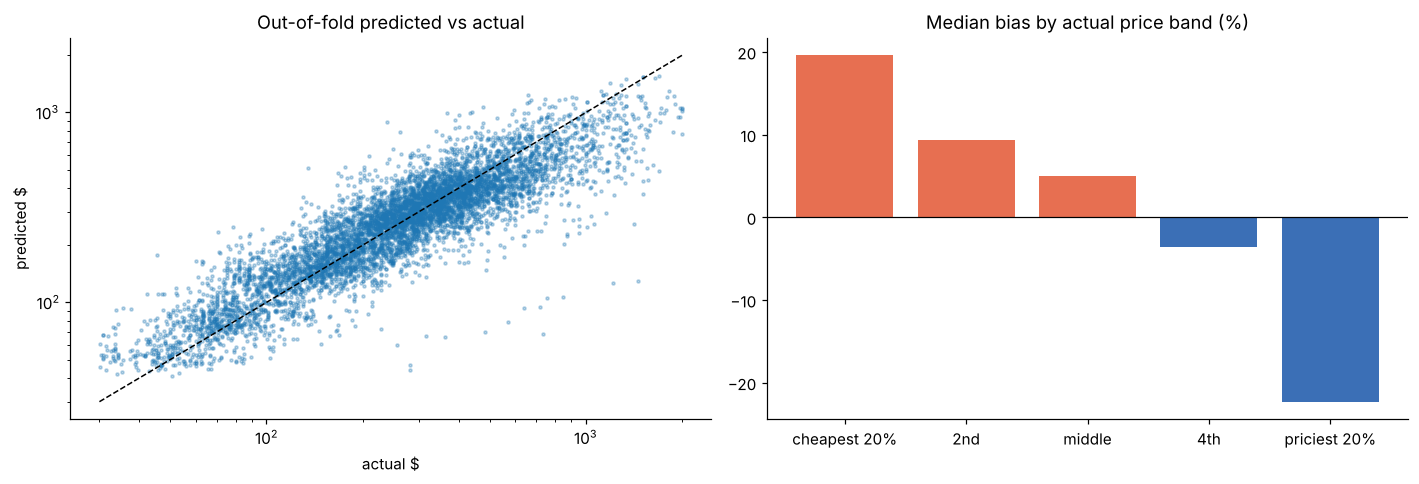

,listings,MAE,bias_pct,within_20
hood,,,,
Longwood Medical Area,43,180.6,-29.7,32.6
South Boston Waterfront,128,137.4,-10.9,33.6
Bay Village,175,142.0,-6.0,56.6
South End,461,81.8,-1.2,58.6


In [9]:
hood_err = seg("hood").query("listings >= 40").sort_values("bias_pct")
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].scatter(E["actual"], E["pred"], s=4, alpha=.3); ax[0].plot([30, 2000], [30, 2000], "k--", lw=1)
ax[0].set_xscale("log"); ax[0].set_yscale("log"); ax[0].set_title("Out-of-fold predicted vs actual"); ax[0].set_xlabel("actual $"); ax[0].set_ylabel("predicted $")
pb = segs["price_band"].loc[["cheapest 20%", "2nd", "middle", "4th", "priciest 20%"]]
ax[1].bar(pb.index, pb["bias_pct"], color=np.where(pb["bias_pct"] > 0, "#e76f51", "#3b6fb6")); ax[1].axhline(0, color="k", lw=.8)
ax[1].set_title("Median bias by actual price band (%)"); plt.tight_layout(); plt.show()
hood_err.head(4).round(1)

**Regression to the middle.** The model over-prices the cheapest listings and under-prices the most expensive. This is the typical failure of any model that is unsure: it pulls predictions toward the average. Part of it is unavoidable. Very cheap and very expensive prices often come from things the data can't see, like a promotion, a luxury renovation, or a listing priced for a special event.

## 8. Verdict and what comes next

The tables above give the exact figures; the points below interpret them.

**Overfitting**
* **The model memorises, but that isn't what limits it.** LightGBM's training R² is far above its held-out R², like every tree model. Yet it still has the best held-out error, and its errors move little across the 9 hyperparameter settings.
* **Selection overfitting is the real risk.** Pure-noise features sometimes pass the keep rule, so small gains (well under a dollar) can't be distinguished from luck. The nested test gives the honest value of the merge; gains that survive it are real.
* **Time drift is the biggest practical risk.** A summer-trained model over-prices September. Training on both quarters reduces the bias but doesn't remove it, and the 80% range should be checked on new data before it is trusted.

**Errors to watch**
* Systematic regression to the middle: cheap listings over-priced, luxury ones under-priced.
* Listings without reviews and monthly rentals are harder.
* Inputs the calculator must ask for honestly: the quoted night's day of week is a real driver, so the tool should ask "which night?" rather than assume.

In [10]:
lgb_lc = slope.loc["LightGBM"]; mlp_lc = slope.loc["Neural network (MLP)"]
bundle = json.loads(_js[_js.index("{"): _js.rindex("}") + 1])
bundle["overfit"] = {
    "gap": gapdf.groupby("model")[["train_R2", "heldout_R2", "heldout_MAE"]].mean().round(4).reset_index().to_dict(orient="records"),
    "learning_curve": curve.round(3).to_dict(orient="records"),
    "noise": {"tested": int(len(noise_df)), "kept": int(noise_df["would be kept"].sum()), "max_gain": float(-noise_df["change $"].min()),
              "median_abs_change": float(noise_df["change $"].abs().median())},
    "nested": {"non_nested_change": float(merged_err.mean() - base_err.mean()), "nested_change": float(nested["change $"].mean()),
               "folds_better": int((nested["change $"] < 0).sum()), "chosen": nested["ideas chosen inside the fold"].tolist()},
    "oot": oot.reset_index().round(3).to_dict(orient="records"),
    "sens": {"min": float(sens["CV MAE"].min()), "max": float(sens["CV MAE"].max())},
    "segments": {c: t.reset_index().to_dict(orient="records") for c, t in segs.items()},
    "cv_mae": float(merged_err.mean()),
}
payload = json.dumps(bundle, separators=(",", ":"))
(OUT / "data.js").write_text("window.PRICING = " + payload + ";\n")
print(f"added 'overfit' to interface/data.js ({len(payload) / 1e6:.2f} MB)")

added 'overfit' to interface/data.js (0.26 MB)
